# M1-INF4 — Python Workshop for Data Analysis
## Session 5 — Data Integration Case Study

### A retail decision supported by reliable data
You are a small analytics team working for **Campus Tech**, a fictional retailer of computer accessories and equipment. The manager wants to compare stores before deciding where to investigate further.

> “The store with the highest total sales is our best-performing store. We should copy its approach everywhere.”

**Your mission:** integrate three sources, assess this claim and deliver an evidence-based recommendation.

This is a synthesis project. Use the pandas and Matplotlib techniques from Sessions 1–4. No new library or advanced modelling is required.

**All data are synthetic. Some records deliberately contain quality issues for training.** Findings describe this supplied sample, not a real company.

### What the data represent
The intended scope is **1–28 April 2025 inclusive**. This is an extract of completed orders, **not a complete record of all activity**. Coverage can differ between stores. A day absent from the extract is not evidence of zero sales or store closure.

| File | One row represents | Expected key | Purpose |
|---|---|---|---|
| `case_sales.csv` | One completed order for one product, possibly several units | `order_id` | Recorded quantity and unit selling price |
| `case_stores.csv` | One store | `store_id` | Store name, city and format |
| `case_products.csv` | One product | `product_id` | Product name and category |

Each order concerns **one product only**, so one valid order row is one order, not a line in a multi-product basket. The price is the final selling price per unit in EUR, after discounts and excluding VAT. Returns and cancellations are outside this extract.

Revenue per order = quantity × unit selling price. **Revenue is not profit**: costs, staffing, opening hours and customer traffic are unavailable.

The reference files should have unique keys, but this must be checked. Repeated store or product IDs in the sales file are normal.

### Data dictionary
| Field | Meaning and rule |
|---|---|
| `order_id` | Order identifier, required and unique after removing exact repeated records |
| `date` | Order date, expected format `YYYY-MM-DD`, within the study window |
| `store_id`, `product_id` | Reference keys; trim spaces and normalise case before joining |
| `quantity` | Positive whole number of units |
| `unit_price_eur` | Positive numeric unit price; a decimal comma may occur |
| `store_name`, `city`, `store_format` | Store attributes; “Small”/“Large” describes format, not observed floor area |
| `product_name`, `category` | Product attributes |

**Quality policy:** keep raw objects unchanged. Remove exact duplicate rows with an audit count. Convert invalid dates/numbers to missing values. Keep invalid or unmatched records in review tables, without inventing replacements. Do not remove a large but valid order simply because it is unusual. If duplicate reference keys disagree, investigate rather than arbitrarily keeping the first row.

### Files and group deliverable
Place this notebook in `notebooks/` and the three CSV files in the neighbouring `data/` folder. You may also put the CSV files beside the notebook.

Submit one completed notebook per group, the exported summary tables and three labelled figures. Record group members below. Divide the work, then review the entire analysis together: **every member must be able to explain the data unit, cleaning choices, joins and conclusions**.

Group members: Horia Filip Radulescu, Oumnia Hannouni, Fariza Faradji, Noraiz Aziz.

The sections below form one continuous analysis. Each checkpoint is a review of your own results, not a separate dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('../data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in
    ['case_sales.csv', 'case_stores.csv', 'case_products.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three case_*.csv files in data/ or beside this notebook.')
OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(exist_ok=True)

sales_raw = pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string')
stores_raw = pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string')
products_raw = pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string')
for name, frame in [('Sales', sales_raw), ('Stores', stores_raw), ('Products', products_raw)]:
    print(name, frame.shape)
    display(frame.head())

Sales (252, 6)


,order_id,date,store_id,product_id,quantity,unit_price_eur
0,O0001,2025-04-21,s1,P02,3,19.90
1,O0002,2025-04-14,S1,p02,2,39.90
2,O0003,2025-04-14,S1,P04,1,"179,00"
3,O0004,2025-04-31,S1,P03,1,179.00
4,O0005,2025-04-09,S1,P02,two,19.90


Stores (4, 4)


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Products (7, 3)


,product_id,product_name,category
0,P01,Keyboard,Accessories
1,P02,Mouse,Accessories
2,P03,Monitor,Screens
3,P04,Headset,Audio
4,P05,Webcam,Video


## 1. Understand and audit the sources
1. Report row and column counts, missing values and exact duplicate counts for each source.
2. Check the expected keys. Explain why repeated `store_id` values are acceptable in sales but potentially dangerous in stores.
3. Write the observation unit and the proposed join keys before joining anything.

**Checkpoint:** your audit should distinguish missing data, repeated records and normal repeated foreign keys.

In [2]:
sources = {
    "Sales": sales_raw,
    "Stores": stores_raw,
    "Products": products_raw
}

expected_key = {
    "Sales": "order_id",
    "Stores": "store_id",
    "Products": "product_id"
}

audit_rows = []

for name, df in sources.items():
    key = expected_key[name]

    # Count repeated non-missing key values
    repeated_keys = int(
        df.loc[df[key].notna(), key].duplicated().sum()
    )

    # Repeated primary keys are dangerous
    dangerous_key_repeated = (
        repeated_keys if name in ["Stores", "Products"] else 0
    )

    audit_rows.append({
        "source": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "missing_cells": int(df.isna().sum().sum()),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "key": key,
        "key_missing": int(df[key].isna().sum()),
        "normal_key_repeated": repeated_keys,
        "dangerous_key_repeated": dangerous_key_repeated
    })

audit = pd.DataFrame(audit_rows).set_index("source")
display(audit)

print(
    "Repeated store_id values are acceptable in Sales because "
    "store_id is a foreign key there. They are potentially dangerous "
    "in Stores because store_id should be a primary key."
)

print(
    "Observation units:\n"
    "- Sales: each record represents a sale of a product at a store "
    "on a given date.\n"
    "- Stores: each record represents one store.\n"
    "- Products: each record represents one product."
)

print(
    "Proposed join keys:\n"
    "- Sales to Stores: store_id.\n"
    "- Sales to Products: product_id."
)

,rows,columns,missing_cells,exact_duplicate_rows,key,key_missing,normal_key_repeated,dangerous_key_repeated
source,,,,,,,,
Sales,252,6,1,2,order_id,0,2,0
Stores,4,4,0,0,store_id,0,0,0
Products,7,3,0,1,product_id,0,1,1


Repeated store_id values are acceptable in Sales because store_id is a foreign key there. They are potentially dangerous in Stores because store_id should be a primary key.
Observation units:
- Sales: each record represents a sale of a product at a store on a given date.
- Stores: each record represents one store.
- Products: each record represents one product.
Proposed join keys:
- Sales to Stores: store_id.
- Sales to Products: product_id.


**Your interpretation**

One row is one order in `case_sales.csv`, one store in `case_stores.csv`, one product in `case_products.csv`. `store_id` links sales to stores, `product_id` links sales to products.

Repeated `store_id` in sales is normal, a store has many orders. A repeated `store_id` in `stores` would be dangerous, since it's meant to identify exactly one store there, and could match one order to two store rows and duplicate it. `stores` is clean, but `products` has one exact duplicate (`P01`), harmless since it's identical, though it still needs removing before the join.

## 2. Prepare reliable tables
Create working copies. Apply the quality policy above.

1. Count and remove **exact** duplicate records in all three tables.
2. Normalise identifiers, parse dates and convert the two numeric fields. Handle decimal commas.
3. Flag missing IDs, failed conversions, non-positive prices, quantities that are not positive integers, and dates outside the study window.
4. Produce `sales_valid` and `sales_review`. Keep the rejected records and the reason flags.
5. Validate unique, non-missing reference keys and unique valid order IDs.

**Checkpoint:** input rows = exact duplicates removed + invalid rows retained for review + valid rows. Multiple reason flags can describe the same rejected row, so do not sum flags as if they were distinct rows.

In [3]:
# 1
sales = sales_raw.copy()
stores = stores_raw.copy()
products = products_raw.copy()

input_rows = len(sales)   # point de départ de la réconciliation

# Comptage avant la suppression
dup_counts = {
    "sales": int(sales.duplicated().sum()),
    "stores": int(stores.duplicated().sum()),
    "products": int(products.duplicated().sum()),
}
print(dup_counts)

# Suppression
sales = sales.drop_duplicates().reset_index(drop=True)
stores = stores.drop_duplicates().reset_index(drop=True)
products = products.drop_duplicates().reset_index(drop=True)

#2 :

for df, cols in [(sales, ["order_id", "store_id", "product_id"]),
                 (stores, ["store_id"]),
                 (products, ["product_id"])]:
    for c in cols:
        df[c] = df[c].str.strip().str.upper()

# Date
sales["date_parsed"] = pd.to_datetime(
    sales["date"].str.strip(), format="%Y-%m-%d", errors="coerce"
)

# Quantité
sales["quantity_num"] = pd.to_numeric(sales["quantity"].str.strip(), errors="coerce")

# Prix
sales["unit_price_num"] = pd.to_numeric(
    sales["unit_price_eur"].str.strip().str.replace(",", ".", regex=False),
    errors="coerce",
)

# 3. flag issues (one boolean column per reason, a row can trigger more than one)
study_start = pd.Timestamp("2025-04-01")
study_end = pd.Timestamp("2025-04-28")
reason_missing_id = sales["order_id"].isna() | sales["store_id"].isna() | sales["product_id"].isna()
reason_invalid_date = sales["date_parsed"].isna() | (sales["date_parsed"] < study_start) | (sales["date_parsed"] > study_end)
reason_invalid_price = sales["unit_price_num"].isna() | (sales["unit_price_num"] <= 0)
reason_invalid_quantity = (
    sales["quantity_num"].isna()
    | (sales["quantity_num"] <= 0)
    | (sales["quantity_num"] % 1 != 0)
)
invalid_mask = reason_missing_id | reason_invalid_date | reason_invalid_price | reason_invalid_quantity

# 4. sales_valid and sales_review, keeping the reason flags
sales_review = sales.loc[invalid_mask, ["order_id", "date", "store_id", "product_id", "quantity", "unit_price_eur"]].copy()
sales_review["reason_missing_id"] = reason_missing_id[invalid_mask]
sales_review["reason_invalid_date"] = reason_invalid_date[invalid_mask]
sales_review["reason_invalid_price"] = reason_invalid_price[invalid_mask]
sales_review["reason_invalid_quantity"] = reason_invalid_quantity[invalid_mask]

sales_valid = sales.loc[~invalid_mask, ["order_id", "store_id", "product_id"]].copy()
sales_valid["date"] = sales.loc[~invalid_mask, "date_parsed"]
sales_valid["quantity"] = sales.loc[~invalid_mask, "quantity_num"].astype(int)
sales_valid["unit_price_eur"] = sales.loc[~invalid_mask, "unit_price_num"]

print()
print("sales_valid rows:", len(sales_valid))
print("sales_review rows:", len(sales_review))
display(sales_review[["order_id", "reason_missing_id", "reason_invalid_date", "reason_invalid_price", "reason_invalid_quantity"]])

# row accounting: do not sum the 4 flag columns, a row can carry more than one flag
assert len(sales) == len(sales_valid) + len(sales_review)

# 5. validate reference keys and order IDs
stores_clean = stores
products_clean = products
duplicate_rows_removed = dup_counts["sales"]

assert stores_clean["store_id"].notna().all() and stores_clean["store_id"].is_unique
assert products_clean["product_id"].notna().all() and products_clean["product_id"].is_unique
assert sales_valid["order_id"].notna().all() and sales_valid["order_id"].is_unique
print("Reference keys and valid order IDs are unique and non-missing.")

{'sales': 2, 'stores': 0, 'products': 1}

sales_valid rows: 243
sales_review rows: 7


,order_id,reason_missing_id,reason_invalid_date,reason_invalid_price,reason_invalid_quantity
3,O0004,False,True,False,False
4,O0005,False,False,False,True
5,O0006,False,False,True,False
6,O0007,False,False,False,True
7,O0008,False,False,True,False
8,O0009,False,False,False,True
11,O0012,False,True,False,False


Reference keys and valid order IDs are unique and non-missing.


**Your interpretation**

Which records did you exclude, repair or keep? Why?

We removed duplicate rows from Sales and Products. We standardized IDs, dates, and numeric values to ensure consistency. We set aside 7 sales records with invalid dates, prices, or quantities in `sales_review` because they could not be reliably corrected. We kept the remaining 243 records in `sales_valid` because they passed the validation checks.

## 3. Integrate and reconcile
1. Join `sales_valid` to stores with a **left join**, `validate="many_to_one"` and an indicator. Inspect unmatched keys.
2. Join that result to products with the same controls. Use a different indicator name, or rename/remove the first indicator before the second join.
3. Check that neither join changes the row count.
4. Keep orders missing either reference in `integration_review`. Create `analysis` using orders matched to **both** references.
5. Present a reconciliation table from raw input to the final analytical population.

**Checkpoint:** never interpret an unknown product as zero revenue, and never allow a duplicated reference key to multiply orders. State how many orders the analysis excludes.

In [4]:
# Join the sources and audit coverage

# 1. left join to stores
with_store = sales_valid.merge(
    stores_clean, on="store_id", how="left", validate="many_to_one", indicator="store_match"
)
assert len(with_store) == len(sales_valid)  # 3. row count unchanged after the store join
print("Store match:")
print(with_store["store_match"].value_counts())

# 2. left join to products
with_both = with_store.merge(
    products_clean, on="product_id", how="left", validate="many_to_one", indicator="product_match"
)
assert len(with_both) == len(with_store)  # 3. row count unchanged after the product join
print()
print("Product match:")
print(with_both["product_match"].value_counts())

# 4. split: unmatched orders go to integration_review, the rest become analysis
unmatched = with_both["store_match"].eq("left_only") | with_both["product_match"].eq("left_only")
integration_review = with_both.loc[unmatched].copy()
analysis = with_both.loc[~unmatched].drop(columns=["store_match", "product_match"]).copy()

print()
print("Orders excluded for an unmatched store or product reference:", len(integration_review))
display(integration_review[["order_id", "store_id", "product_id", "store_match", "product_match"]])
print("analysis rows:", len(analysis))

# 5. reconciliation table
reconciliation = pd.DataFrame([
    {"stage": "Raw sales rows", "rows": len(sales_raw)},
    {"stage": "Exact duplicate rows removed", "rows": -duplicate_rows_removed},
    {"stage": "Invalid rows set aside (sales_review)", "rows": -len(sales_review)},
    {"stage": "Unmatched reference set aside (integration_review)", "rows": -len(integration_review)},
    {"stage": "Final analysis population", "rows": len(analysis)},
])
display(reconciliation)

assert len(sales_raw) == duplicate_rows_removed + len(sales_review) + len(integration_review) + len(analysis)

Store match:
store_match
both          242
left_only       1
right_only      0
Name: count, dtype: int64

Product match:
product_match
both          242
left_only       1
right_only      0
Name: count, dtype: int64

Orders excluded for an unmatched store or product reference: 2


,order_id,store_id,product_id,store_match,product_match
3,O0010,S99,P06,left_only,both
4,O0011,S1,P99,both,left_only


analysis rows: 241


,stage,rows
0,Raw sales rows,252
1,Exact duplicate rows removed,-2
2,Invalid rows set aside (sales_review),-7
3,Unmatched reference set aside (integration_rev...,-2
4,Final analysis population,241


**Your interpretation**

A left join keeps every row from `sales_valid`, matched or not, so it's the only way to actually see which orders reference a store or product ID that doesn't exist (`S99`, `P99`). An inner join would have dropped those two orders silently, with no record of what was removed or why. Joining left first, then checking `store_match`/`product_match` before splitting into `analysis` and `integration_review`, keeps a clear trail of what got excluded and why.

## 4. Build indicators that answer the question
For each order in `analysis`, calculate `revenue_eur`.

Create `store_summary` with, for each store:
- order count and total units;
- total revenue (EUR);
- mean and median revenue per order (EUR).

Also create a revenue summary by product category and a daily revenue table for each store. Check that the totals reconcile with the order-level revenue.

Compare the store with the highest total revenue to the store with the highest mean revenue per order. Do they coincide? Explain the role of order counts and product mix.

**Important:** `quantity` counts units, not orders. Mean revenue per order = total revenue / number of orders. Round for presentation, not before aggregation. Avoid calling this a profitability or productivity ranking.

In [5]:
# Compute order-level and aggregated indicators
# Requires `analysis` from section 3: one row = one valid order matched to a store AND a product.

# 1. Revenue of each order (EUR, excl. VAT). No rounding at this stage.
analysis["revenue_eur"] = analysis["quantity"].astype(float) * analysis["unit_price_eur"].astype(float)

# 2. Store summary
store_summary = analysis.groupby(["store_id", "store_name"], as_index=False).agg(
    n_orders=("order_id", "nunique"),
    total_units=("quantity", "sum"),
    total_revenue_eur=("revenue_eur", "sum"),
    median_order_revenue_eur=("revenue_eur", "median"),
)
# Mean per order computed explicitly as total / number of orders
store_summary["mean_order_revenue_eur"] = store_summary["total_revenue_eur"] / store_summary["n_orders"]
store_summary = store_summary.sort_values("total_revenue_eur", ascending=False, ignore_index=True)
print("Store summary (rounded for display only):")
display(store_summary.round(2))

# 3. Revenue by product category
category_summary = analysis.groupby("category", as_index=False).agg(
    n_orders=("order_id", "nunique"),
    total_units=("quantity", "sum"),
    total_revenue_eur=("revenue_eur", "sum"),
)
category_summary["share_of_revenue_pct"] = 100 * category_summary["total_revenue_eur"] / category_summary["total_revenue_eur"].sum()
category_summary = category_summary.sort_values("total_revenue_eur", ascending=False, ignore_index=True)
print("Revenue by category:")
display(category_summary.round(2))

# 4. Daily revenue per store on the full calendar 1–28 April 2025.
#    pivot_table gives one column per store; reindex adds absent days as NaN (missing, not zero).
calendar = pd.date_range("2025-04-01", "2025-04-28", freq="D", name="date")
daily_revenue = (
    analysis.pivot_table(index="date", columns="store_name", values="revenue_eur", aggfunc="sum")
    .reindex(calendar)
)
print("Days with at least one recorded order, per store (out of 28):")
display(daily_revenue.count().to_frame("days_with_orders"))

# 5. Reconciliation with the order-level revenue
total_orders_level = analysis["revenue_eur"].sum()
checks = pd.Series({
    "order level": total_orders_level,
    "store_summary": store_summary["total_revenue_eur"].sum(),
    "category_summary": category_summary["total_revenue_eur"].sum(),
    "daily_revenue": daily_revenue.sum().sum(),   # NaN are skipped, not counted as 0
}, name="total_revenue_eur")
display(checks.round(2).to_frame())
assert np.allclose(checks, total_orders_level), "Totals do not reconcile"
assert store_summary["n_orders"].sum() == len(analysis)

# 6. Same leader for total and for mean per order?
leader_total = store_summary.loc[store_summary["total_revenue_eur"].idxmax(), "store_name"]
leader_mean = store_summary.loc[store_summary["mean_order_revenue_eur"].idxmax(), "store_name"]
print(f"Highest total revenue:          {leader_total}")
print(f"Highest mean revenue per order: {leader_mean}")
print("Same store?", leader_total == leader_mean)

# 7. Product mix: share of each store's revenue by category (denominator = the store's revenue)
mix = pd.crosstab(analysis["store_name"], analysis["category"],
                  values=analysis["revenue_eur"], aggfunc="sum", normalize="index") * 100
print("Share of each store's revenue by category (%):")
display(mix.round(1))


Store summary (rounded for display only):


,store_id,store_name,n_orders,total_units,total_revenue_eur,median_order_revenue_eur,mean_order_revenue_eur
0,S2,Paris Est,70,116,10528.9,79.80,150.41
1,S1,Paris Centre,91,155,6482.9,39.90,71.24
2,S4,Lille Centre,30,51,5712.5,158.50,190.42
3,S3,Lyon Centre,50,86,4982.5,64.45,99.65


Revenue by category:


,category,n_orders,total_units,total_revenue_eur,share_of_revenue_pct
0,Screens,45,81,14499.0,52.33
1,Accessories,133,224,6427.6,23.20
2,Video,32,54,3726.0,13.45
3,Audio,31,49,3054.2,11.02


Days with at least one recorded order, per store (out of 28):


,days_with_orders
store_name,
Lille Centre,20
Lyon Centre,22
Paris Centre,27
Paris Est,25


,total_revenue_eur
order level,27706.8
store_summary,27706.8
category_summary,27706.8
daily_revenue,27706.8


Highest total revenue:          Paris Est
Highest mean revenue per order: Lille Centre
Same store? False
Share of each store's revenue by category (%):


category,Accessories,Audio,Screens,Video
store_name,,,,
Lille Centre,7.3,1.0,78.3,13.3
Lyon Centre,31.0,15.6,39.5,13.8
Paris Centre,49.6,15.7,16.6,18.1
Paris Est,11.8,11.4,66.3,10.5


**Your interpretation**

No. **Paris Est** records the highest total revenue (≈ 10,529 EUR over 70 orders), but **Lille Centre** records the highest mean revenue per order (≈ 190 EUR, median 158.50 EUR) with only 30 orders and the third-highest total. Paris Centre is the opposite case: it has the most orders (91) and units (155) but the smallest orders on average (≈ 71 EUR, median 39.90 EUR).

A total is the product of two things: *how many* orders were recorded and *how large* each order is. Paris Est combines a fairly high number of orders with fairly large orders, which is why it leads on total without leading on either factor alone. Product mix explains much of the order size: monitors (179 EUR per unit) make up about 78 % of Lille Centre's revenue and about 66 % of Paris Est's, but only about 17 % of Paris Centre's, which mainly sells low-priced accessories. The number of recorded orders also depends on the coverage of the extract (20 to 27 days out of 28 depending on the store), so neither ranking is a measure of profitability or productivity.


## 5. Communicate with three complementary figures
Before coding each figure, write **the question**, **the observation unit** and **the aggregation**.

1. A bar chart comparing total revenue by store, with order counts available alongside it.
2. A boxplot of order revenue by store, showing centre, spread and atypical values. Display group sizes. Do not remove atypical values without evidence of error.
3. A line chart of daily revenue by store over the study window. Use chronological dates, one labelled colour per store and a common calendar. **Leave missing store-days as missing**, not zero, because this is an extract.

Use clear titles, units, readable labels and legends when needed. Add a two-sentence interpretation and a limitation for each figure. Explain why the three figures answer different questions.

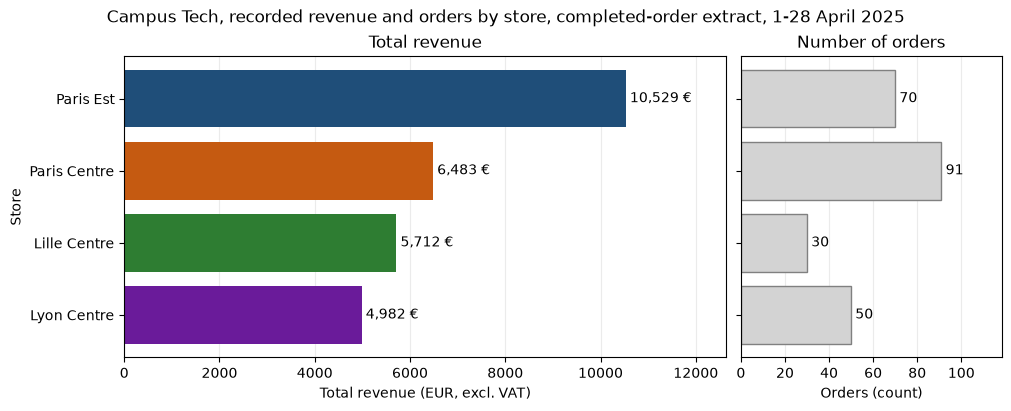

In [6]:
# Figure 1 — Total revenue by store
# Question: which store recorded the most revenue, and with how many orders?
# Unit: one order of `analysis`. Aggregation: sum of revenue_eur and count of orders per store.
import matplotlib.dates as mdates

STORES = store_summary["store_name"].tolist()            # sorted by total revenue (descending)
COLOURS = dict(zip(STORES, ["#1f4e79", "#c55a11", "#2e7d32", "#6a1b9a"]))

fig, (ax_rev, ax_n) = plt.subplots(1, 2, figsize=(10, 4), sharey=True,
                                   gridspec_kw={"width_ratios": [3, 1.3]}, layout="constrained")
y = range(len(STORES))
bars = ax_rev.barh(y, store_summary["total_revenue_eur"], color=[COLOURS[s] for s in STORES])
ax_rev.bar_label(bars, labels=[f"{v:,.0f} €" for v in store_summary["total_revenue_eur"]], padding=3)
ax_rev.set_yticks(list(y), STORES)
ax_rev.invert_yaxis()
ax_rev.set_xlim(0, store_summary["total_revenue_eur"].max() * 1.2)
ax_rev.set(xlabel="Total revenue (EUR, excl. VAT)", ylabel="Store", title="Total revenue")

bars_n = ax_n.barh(y, store_summary["n_orders"], color="lightgrey", edgecolor="grey")
ax_n.bar_label(bars_n, padding=3)
ax_n.set_xlim(0, store_summary["n_orders"].max() * 1.3)
ax_n.set(xlabel="Orders (count)", title="Number of orders")

for ax in (ax_rev, ax_n):
    ax.grid(axis="x", alpha=.25)
    ax.set_axisbelow(True)
fig.suptitle("Campus Tech, recorded revenue and orders by store, completed-order extract, 1-28 April 2025")
fig.savefig(OUT_DIR / "figure1_total_revenue_by_store.png", dpi=150, bbox_inches="tight")
plt.show()

**Your interpretation**

*Question:* which store recorded the most revenue in the extract? *Unit:* one valid, matched order. *Aggregation:* sum of `revenue_eur` per store, with the count of orders shown in the right-hand panel.

Paris Est clearly leads on total revenue (≈ 10,529 EUR), about 4,000 EUR more than Paris Centre, even though Paris Centre recorded 21 more orders. The two panels do not give the same ranking: Lille Centre has the fewest orders but the third-highest total, so volume alone does not explain the total. **Limitation:** these are totals of an *extract* of completed orders; a store whose activity is less well captured will look smaller, and revenue says nothing about costs or profit.


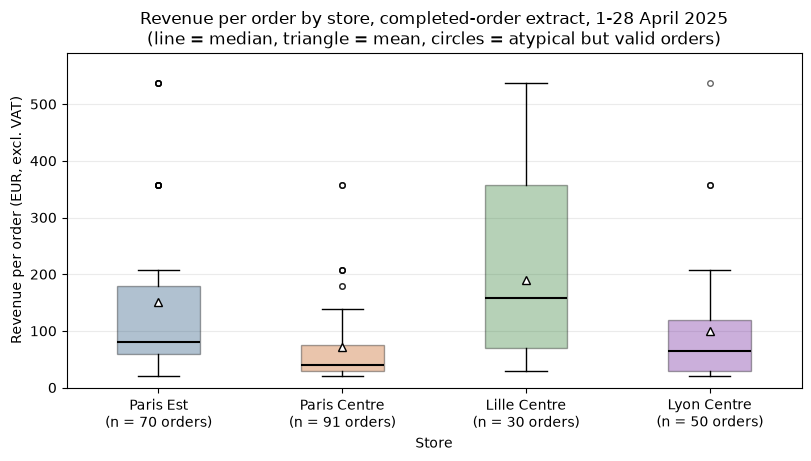

In [7]:
# Figure 2 — Distribution of order revenue
# Question: how large is a typical order in each store, and how much do order amounts vary?
# Unit: one order. Aggregation: none before plotting (the boxplot summarises each store's orders).
data_by_store = [analysis.loc[analysis["store_name"].eq(s), "revenue_eur"] for s in STORES]

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
box = ax.boxplot(data_by_store, patch_artist=True, showmeans=True,
                 meanprops={"marker": "^", "markerfacecolor": "white", "markeredgecolor": "black"},
                 medianprops={"color": "black", "linewidth": 1.5},
                 flierprops={"marker": "o", "markersize": 4, "alpha": .6})
for patch, s in zip(box["boxes"], STORES):
    patch.set_facecolor(COLOURS[s])
    patch.set_alpha(.35)
ax.set_xticks(range(1, len(STORES) + 1), [f"{s}\n(n = {len(d)} orders)" for s, d in zip(STORES, data_by_store)])
ax.set_ylim(0, analysis["revenue_eur"].max() * 1.1)
ax.set(title="Revenue per order by store, completed-order extract, 1-28 April 2025\n(line = median, triangle = mean, circles = atypical but valid orders)",
       xlabel="Store", ylabel="Revenue per order (EUR, excl. VAT)")
ax.grid(axis="y", alpha=.25)
ax.set_axisbelow(True)
fig.savefig(OUT_DIR / "figure2_order_revenue_by_store.png", dpi=150, bbox_inches="tight")
plt.show()

**Your interpretation**

*Question:* how large and how variable are individual orders in each store? *Unit:* one order (quantity × unit price).

Lille Centre's orders are the largest and the most spread out (median 158.50 EUR, box from about 70 to 360 EUR), whereas Paris Centre's are small and concentrated (median 39.90 EUR, most orders below 100 EUR). In every store the mean (triangle) sits above the median. A handful of large orders, usually two or three monitors and up to 537 EUR, pull it up; they're plausible valid orders, so we kept them rather than removing them. **Limitation:** Lille Centre's distribution rests on only 30 orders, so its median is less stable than Paris Centre's (91 orders), and the boxplot hides that many orders share exactly the same few price points.

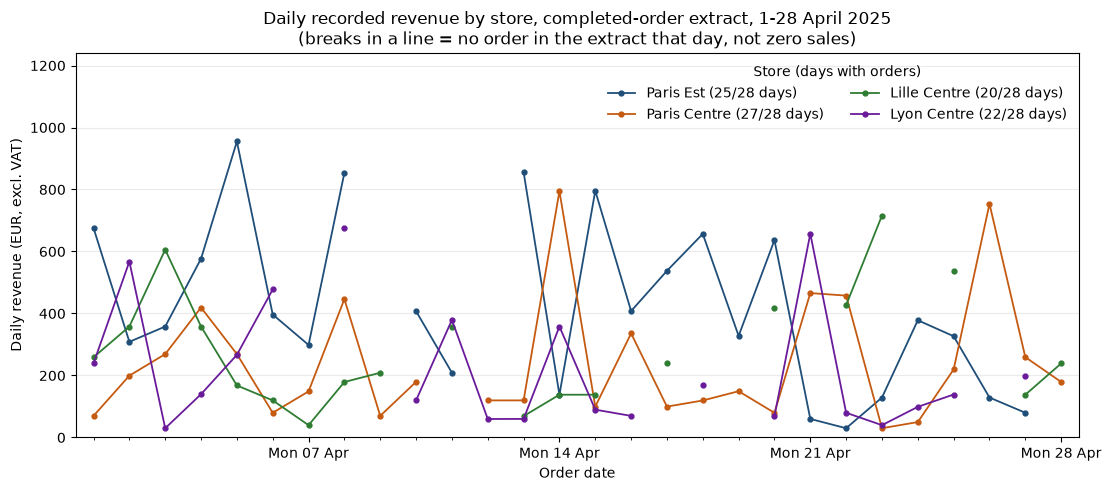

In [8]:
# Figure 3 — Daily sampled revenue
# Question: how is each store's revenue spread over the study window?
# Unit: one store-day. Aggregation: sum of revenue_eur per store and date, on the full 1-28 April calendar.
# Absent store-days stay NaN: matplotlib breaks the line instead of drawing a false zero.
fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
for s in STORES:
    values = daily_revenue[s].astype(float)
    ax.plot(daily_revenue.index, values, color=COLOURS[s], marker="o", markersize=3.5,
            linewidth=1.3, label=f"{s} ({values.notna().sum()}/28 days)")
ax.set_xlim(calendar.min() - pd.Timedelta(days=0.5), calendar.max() + pd.Timedelta(days=0.5))
ax.set_ylim(0, daily_revenue.max().max() * 1.3)  # headroom for the legend
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_minor_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
ax.set(title="Daily recorded revenue by store, completed-order extract, 1-28 April 2025\n(breaks in a line = no order in the extract that day, not zero sales)",
       xlabel="Order date", ylabel="Daily revenue (EUR, excl. VAT)")
ax.legend(title="Store (days with orders)", frameon=False, ncol=2, loc="upper right")
ax.grid(axis="y", alpha=.25)
fig.savefig(OUT_DIR / "figure3_daily_revenue_by_store.png", dpi=150, bbox_inches="tight")
plt.show()

**Your interpretation**

*One point* is the total revenue of one store on one day (sum of that store's orders on that date). Days were placed on a common calendar from 1 to 28 April. When a store has no order in the extract for a day, the value was left **missing**, so the line breaks instead of dropping to zero. An absent day may just be a gap in the extract, not a day without sales.

Daily revenue is very irregular for all four stores: a single day with a few monitor orders can reach several hundred euros, so the four-week totals of Figure 1 are sensitive to a handful of large orders. Coverage also differs, from 27 days for Paris Centre to 20 for Lille Centre, which limits direct comparisons of totals. **Limitation:** four weeks are too short to separate a trend or a weekly pattern from noise.

**Why three figures?** Figure 1 answers how much in total, Figure 2 how large a single order typically is and how variable, and Figure 3 when the revenue was recorded and how complete each store's coverage is. Only the three together show that the highest total (Paris Est) and the largest typical order (Lille Centre) belong to different stores.

## 6. Write a decision brief
Write **six to eight sentences** addressed to the manager. Include:
- a clear answer to the original claim;
- at least two numerical results, with units and population;
- a distinction between total revenue and mean or median order revenue;
- a data-quality or integration limitation and a sample-coverage limitation;
- one plausible explanation labelled as a hypothesis;
- one proportionate next action and the extra data needed.

Avoid “Store X is best” without defining best. Do not claim causality, profitability or complete activity from this extract.

**Your interpretation**

The claim doesn't fully hold up. Paris Est has the highest total revenue (about 10,529 EUR over 70 orders), but Lille Centre has the highest average order value (about 190 EUR, median 158.50 EUR) with only 30 orders. Paris Centre sits at the other end: 91 orders, the most of any store, but the smallest average order at about 71 EUR. A likely explanation, not yet confirmed, is product mix: Screens make up 78% of Lille Centre's revenue and 66% of Paris Est's, against 17% for Paris Centre, which sells mostly cheap Accessories. Two limitations matter here. First, cleaning and the join excluded 11 of the 252 recorded sales rows (2 exact duplicates, 7 with a bad date, price or quantity, and 2 referencing an unknown store or product), leaving 241 orders in the analysis. Second, this is a four-week extract with uneven coverage between stores, from 20 to 27 days out of 28, so a quiet day isn't proof of no sales, and revenue isn't profit since we have no cost data. Before copying Paris Est's approach everywhere, we'd want to check whether the product mix difference actually explains the gap, which means getting cost data per category rather than just revenue.

## 7. Export and reproduce
Save `store_summary.csv`, `category_summary.csv`, `reconciliation.csv`, `sales_review.csv` and `integration_review.csv` into `case_study_outputs/`. Save the three figures as PNG files. Use `index=False` for tables.

Before submitting:
- restart the kernel and run all cells from top to bottom;
- check that joins did not multiply rows and revenue totals reconcile;
- check that raw files remain unchanged;
- remove abandoned trials and explain all final decisions;
- make sure every member can explain one cleaning decision, one join control and every chart.

The deliverable is the entire completed notebook, including interpretations, not just the first figure.

In [9]:
# Export the evidence
store_summary.to_csv(OUT_DIR / "store_summary.csv", index=False)
category_summary.to_csv(OUT_DIR / "category_summary.csv", index=False)
reconciliation.to_csv(OUT_DIR / "reconciliation.csv", index=False)
sales_review.to_csv(OUT_DIR / "sales_review.csv", index=False)
integration_review.to_csv(OUT_DIR / "integration_review.csv", index=False)

print("Exported to", OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print(" -", f.name)

assert len(sales_raw) == 252

Exported to C:\Users\Horia\OneDrive\Desktop\Master M1 IBI\Atelier Python ISI 4\notebooks\case_study_outputs
 - category_summary.csv
 - figure1_total_revenue_by_store.png
 - figure2_order_revenue_by_store.png
 - figure3_daily_revenue_by_store.png
 - integration_review.csv
 - reconciliation.csv
 - sales_review.csv
 - store_summary.csv


### OPTIONAL / IF TIME ALLOWS — Investigate product mix
Create a store × category table of revenue or order counts. Use a labelled heatmap or compare category shares within each store. State the denominator explicitly. Does the mix help explain different order amounts? Treat this as descriptive evidence, not a causal proof.

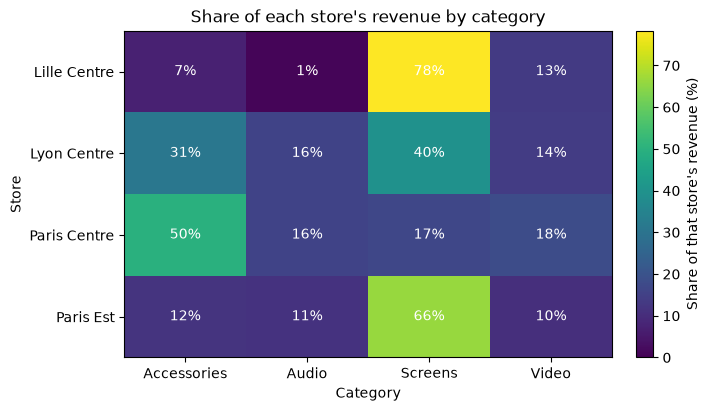

In [10]:
# Optional: product mix heatmap (denominator = each store's own total revenue)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
colourmap = plt.get_cmap("viridis")
im = ax.imshow(mix.to_numpy(dtype=float), aspect="auto", cmap=colourmap, vmin=0)
ax.set_xticks(range(len(mix.columns)), mix.columns)
ax.set_yticks(range(len(mix.index)), mix.index)
for i in range(mix.shape[0]):
    for j in range(mix.shape[1]):
        ax.text(j, i, f"{mix.iloc[i, j]:.0f}%", ha="center", va="center", color="white")
ax.set(title="Share of each store's revenue by category", xlabel="Category", ylabel="Store")
fig.colorbar(im, ax=ax, label="Share of that store's revenue (%)")
plt.show()

The mix lines up with the order-size differences from section 4: Screens take up 78% of Lille Centre's revenue and 66% of Paris Est's, against only 17% for Paris Centre, which leans on Accessories (50%) instead. That's descriptive, not proof. It doesn't tell us why each store sells what it sells, only that the stores with more Screens also have the larger orders.